# 10 — Uncertainty and conformal intervals

**Project:** Hotel overbooking decision support  
**Stage:** Quantify uncertainty in nightly cancellation totals  
**Purpose:** Compare a probability-based uncertainty estimate with an empirical conformal interval.

The model estimates a cancellation probability for each booking. For a hotel-arrival night, we add the probabilities to estimate the expected number of cancellations.

But the expected value is not the actual number. This notebook examines the uncertainty around that nightly total.

We compare:
1. A normal-approximation interval based on the sum of booking-level Bernoulli variances.
2. A split-conformal interval based on historical absolute errors in nightly cancellation counts.

**Important:** These are intervals for cancellation counts, not physical room availability, occupancy or actual guest walks. The historical data is retrospective, and temporal drift can weaken coverage guarantees.

In [1]:
# Run from the repository root, so `from src import ...` and the relative evidence/ paths work
# whether this notebook is opened from the repo folder or from notebooks/pipeline/.
import os
import sys
from pathlib import Path

REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "contract.py").exists())
os.chdir(REPO_ROOT)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
print("Working directory:", REPO_ROOT)

Working directory: C:\Users\Lenovo\Desktop\Build_2_Repo\IIT_GN_W06


## 1. Load the data and create chronological periods

In [2]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src import data, contract

raw = data.read_raw()
bookings = raw.copy()
bookings["arrival_date"] = data.arrival_date(bookings)
bookings["nights"] = (
    bookings["stays_in_weekend_nights"] + bookings["stays_in_week_nights"]
)

train, choose, proof = contract.split_periods(bookings)

print("Train:", len(train), "rows")
print("Choose:", len(choose), "rows")
print("Proof:", len(proof), "rows")

Train: 49157 rows
Choose: 29546 rows
Proof: 40687 rows


## 2. Prepare the candidate feature columns

This repeats the feature definition used in the preceding model notebooks. `country` remains held back pending verification that it is available at the original booking timestamp.

In [3]:
categorical_columns = [
    "hotel",
    "market_segment",
    "distribution_channel",
    "agent",
    "company"
]

numeric_columns = [
    "is_repeated_guest",
    "previous_cancellations",
    "previous_bookings_not_canceled"
]

feature_columns = categorical_columns + numeric_columns

def prepare_features(frame):
    X = frame[feature_columns].copy()

    for column in categorical_columns:
        X[column] = X[column].astype("string")

    X["agent"] = X["agent"].fillna("NO_AGENT")
    X["company"] = X["company"].fillna("NO_COMPANY")

    for column in ["hotel", "market_segment", "distribution_channel"]:
        X[column] = X[column].fillna("UNKNOWN_" + column.upper())

    return X

## 3. Set the base model configuration

The cell below reads the model and settings selected by Notebook 08. (Edited 2026-11-18: this previously held a hand-copied placeholder, logistic regression with `C=1.0`, which did not match Notebook 08's actual selection.)

This notebook uses a chronological Train fit/calibration split. It does not fit on all Train rows, because the later Train block is reserved to estimate conformal residuals.

In [4]:
# Read the configuration Notebook 08 selected, instead of copying it by hand
# (a hand-copied placeholder can silently diverge from the actual selection).
import ast

import pandas as pd

selected_08 = pd.read_csv("evidence/hyperparameter_experiments/selected_settings.csv").iloc[0]
BASE_MODEL_NAME = selected_08["model"]
BASE_MODEL_SETTINGS = ast.literal_eval(selected_08["settings"])
assert BASE_MODEL_NAME in {"logistic_regression", "random_forest"}

print("Base model:", BASE_MODEL_NAME)
print("Base settings:", BASE_MODEL_SETTINGS)
print("Source: evidence/hyperparameter_experiments/selected_settings.csv")

Base model: logistic_regression
Base settings: {'C': 0.1}
Source: evidence/hyperparameter_experiments/selected_settings.csv


## 4. Create the model pipeline

The encoder and numeric preprocessing are fitted only on the model-fitting portion of Train.

In [5]:
def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                categorical_columns
            ),
            (
                "numeric",
                Pipeline(steps=[
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler())
                ]),
                numeric_columns
            )
        ],
        remainder="drop"
    )


def make_model():
    if BASE_MODEL_NAME == "logistic_regression":
        estimator = LogisticRegression(
            C=BASE_MODEL_SETTINGS["C"],
            max_iter=1000
        )
    elif BASE_MODEL_NAME == "random_forest":
        estimator = RandomForestClassifier(
            n_estimators=BASE_MODEL_SETTINGS["n_estimators"],
            min_samples_leaf=BASE_MODEL_SETTINGS["min_samples_leaf"],
            random_state=42,
            n_jobs=-1
        )
    else:
        raise ValueError("Unsupported base model")

    return Pipeline(steps=[
        ("preprocess", make_preprocessor()),
        ("model", estimator)
    ])

## 5. Split Train into a model-fit block and a calibration block

We reserve the latest 20% of unique Train arrival dates as the conformal calibration block. The model is fitted on the earlier 80%.

This respects time order. The model does not train on the dates used to calculate the conformal residual quantile.

In [6]:
train_dates = np.array(sorted(train["arrival_date"].unique()))
date_cut_position = int(np.floor(len(train_dates) * 0.80))
date_cut_position = min(max(date_cut_position, 1), len(train_dates) - 1)

fit_dates = train_dates[:date_cut_position]
calibration_dates = train_dates[date_cut_position:]

fit_mask = train["arrival_date"].isin(fit_dates)
calibration_mask = train["arrival_date"].isin(calibration_dates)

fit_rows = train.loc[fit_mask].copy()
calibration_rows = train.loc[calibration_mask].copy()

print(
    "Model fit period:",
    fit_rows["arrival_date"].min().date(),
    "to",
    fit_rows["arrival_date"].max().date()
)
print(
    "Calibration period:",
    calibration_rows["arrival_date"].min().date(),
    "to",
    calibration_rows["arrival_date"].max().date()
)
print("Fit rows:", len(fit_rows))
print("Calibration rows:", len(calibration_rows))

assert fit_rows["arrival_date"].max() < calibration_rows["arrival_date"].min()

Model fit period: 2015-07-01 to 2016-04-17
Calibration period: 2016-04-18 to 2016-06-30
Fit rows: 35768
Calibration rows: 13389


## 6. Fit the model and predict booking cancellation probabilities

The model is fitted on the earlier Train block. It predicts the later Train calibration block and the Choose period.

In [7]:
model = make_model()

X_fit = prepare_features(fit_rows)
y_fit = fit_rows["is_canceled"].astype(int)

model.fit(X_fit, y_fit)

classes = list(model.named_steps["model"].classes_)
positive_position = classes.index(1)

calibration_probability = model.predict_proba(
    prepare_features(calibration_rows)
)[:, positive_position]

choose_probability = model.predict_proba(
    prepare_features(choose)
)[:, positive_position]

print("Calibration probability count:", len(calibration_probability))
print("Choose probability count:", len(choose_probability))

Calibration probability count: 13389
Choose probability count: 29546


## 7. Aggregate bookings into hotel-arrival nights

For each hotel and arrival date:
- `bookings` is the number of booking rows;
- `actual_cancellations` is the observed number of cancellations/no-shows;
- `expected_cancellations` is the sum of booking probabilities;
- `variance` is the sum of \(p_i(1-p_i)\), assuming independent booking outcomes;
- `spread` is the square root of that variance.

The independence assumption is a simplification. Cancellations may be correlated through shared events, groups, weather, channel policies or other factors.

In [8]:
def make_nightly_table(frame, probabilities):
    scored = frame[["hotel", "arrival_date", "is_canceled"]].copy()
    scored["probability"] = np.asarray(probabilities, dtype=float)
    scored["variance_part"] = (
        scored["probability"] * (1 - scored["probability"])
    )

    nightly = scored.groupby(["hotel", "arrival_date"]).agg(
        bookings=("is_canceled", "size"),
        actual_cancellations=("is_canceled", "sum"),
        expected_cancellations=("probability", "sum"),
        variance=("variance_part", "sum")
    )

    nightly["spread"] = np.sqrt(nightly["variance"])
    return nightly

calibration_nights = make_nightly_table(
    calibration_rows,
    calibration_probability
)

choose_nights = make_nightly_table(
    choose,
    choose_probability
)

display(calibration_nights.head())

bookings  actual_cancellations  \
hotel      arrival_date                                   
City Hotel 2016-04-18          96                    23   
           2016-04-19          96                    61   
           2016-04-20         180                    71   
           2016-04-21         116                    49   
           2016-04-22         172                   106   

                         expected_cancellations   variance    spread  
hotel      arrival_date                                               
City Hotel 2016-04-18                 24.043467  17.326507  4.162512  
           2016-04-19                 17.821136  13.915141  3.730300  
           2016-04-20                 66.364258  38.277974  6.186920  
           2016-04-21                 33.271456  22.223111  4.714140  
           2016-04-22                 38.792514  28.446636  5.333539

## 8. Build a normal-approximation interval

For a chosen confidence level, we use:

\[
	ext{expected cancellations} \pm z 	imes 	ext{spread}
\]

We use 1.645 for an approximate 90% interval. The lower limit cannot be below zero and the upper limit cannot exceed the number of bookings.

This approximation relies on the Bernoulli independence assumption and may be inaccurate for small booking counts or correlated outcomes.

In [9]:
NORMAL_Z_90 = 1.645

def add_normal_interval(nightly):
    result = nightly.copy()
    result["normal_lower"] = (
        result["expected_cancellations"] - NORMAL_Z_90 * result["spread"]
    ).clip(lower=0)

    result["normal_upper"] = (
        result["expected_cancellations"] + NORMAL_Z_90 * result["spread"]
    ).clip(upper=result["bookings"])

    return result

calibration_nights = add_normal_interval(calibration_nights)
choose_nights = add_normal_interval(choose_nights)

display(
    choose_nights[
        ["bookings", "actual_cancellations", "expected_cancellations",
         "spread", "normal_lower", "normal_upper"]
    ].head()
)

bookings  actual_cancellations  \
hotel      arrival_date                                   
City Hotel 2016-07-01         141                    68   
           2016-07-02          80                    33   
           2016-07-03          85                    21   
           2016-07-04          92                    30   
           2016-07-05          74                    14   

                         expected_cancellations    spread  normal_lower  \
hotel      arrival_date                                                   
City Hotel 2016-07-01                 38.682796  5.191362     30.143005   
           2016-07-02                 20.004671  3.798314     13.756445   
           2016-07-03                 21.998490  3.971954     15.464625   
           2016-07-04                 22.036249  3.827264     15.740400   
           2016-07-05                 17.153108  3.545908     11.320090   

                         normal_upper  
hotel      arrival_date                
City Hotel 2016-07-01       47.222587  
           2016-07-02       26.252897  
           2016-07-03       28.532354  
           2016-07-04       28.332098  
           2016-07-05       22.986127

## 9. Calculate split-conformal residuals on the Train calibration block

For each calibration hotel-night, calculate the absolute difference between actual and expected cancellations:

\[
r_j = |y_j - \hat{y}_j|
\]

We use the finite-sample conformal quantile for a nominal 90% interval. The same pooled residual quantile is applied to all hotel-arrival nights.

This is a split-conformal construction. Its classical finite-sample coverage statement assumes exchangeability between calibration and future examples. Since these are time-ordered hotel nights, temporal dependence and drift mean that the nominal coverage is not guaranteed in practice.

In [10]:
calibration_nights["absolute_error"] = (
    calibration_nights["actual_cancellations"]
    - calibration_nights["expected_cancellations"]
).abs()

ALPHA = 0.10
number_calibration_nights = len(calibration_nights)

conformal_rank = math.ceil(
    (number_calibration_nights + 1) * (1 - ALPHA)
)

sorted_residuals = np.sort(
    calibration_nights["absolute_error"].to_numpy()
)

if conformal_rank > number_calibration_nights:
    conformal_quantile = float("inf")
else:
    conformal_quantile = float(
        sorted_residuals[conformal_rank - 1]
    )

print("Calibration hotel-nights:", number_calibration_nights)
print("Nominal interval coverage:", 1 - ALPHA)
print("Conformal rank:", conformal_rank)
print("Conformal residual quantile:", conformal_quantile)

Calibration hotel-nights: 148
Nominal interval coverage: 0.9
Conformal rank: 135
Conformal residual quantile: 36.9136929349863


## 10. Apply the conformal interval to Choose

We centre the interval on the expected cancellation count and add/subtract the calibration residual quantile. We clip the result to the possible range from zero to the number of bookings.

The interval is not a direct probability distribution for the cancellation count. It is a range constructed to target empirical coverage under assumptions that may not hold under time drift.

In [11]:
choose_nights["conformal_lower"] = (
    choose_nights["expected_cancellations"] - conformal_quantile
).clip(lower=0)

choose_nights["conformal_upper"] = (
    choose_nights["expected_cancellations"] + conformal_quantile
).clip(upper=choose_nights["bookings"])

display(
    choose_nights[
        ["bookings", "actual_cancellations", "expected_cancellations",
         "normal_lower", "normal_upper", "conformal_lower", "conformal_upper"]
    ].head()
)

bookings  actual_cancellations  \
hotel      arrival_date                                   
City Hotel 2016-07-01         141                    68   
           2016-07-02          80                    33   
           2016-07-03          85                    21   
           2016-07-04          92                    30   
           2016-07-05          74                    14   

                         expected_cancellations  normal_lower  normal_upper  \
hotel      arrival_date                                                       
City Hotel 2016-07-01                 38.682796     30.143005     47.222587   
           2016-07-02                 20.004671     13.756445     26.252897   
           2016-07-03                 21.998490     15.464625     28.532354   
           2016-07-04                 22.036249     15.740400     28.332098   
           2016-07-05                 17.153108     11.320090     22.986127   

                         conformal_lower  conformal_upper  
hotel      arrival_date                                    
City Hotel 2016-07-01           1.769103        75.596489  
           2016-07-02           0.000000        56.918364  
           2016-07-03           0.000000        58.912183  
           2016-07-04           0.000000        58.949942  
           2016-07-05           0.000000        54.066801

## 11. Measure empirical coverage and interval width

Coverage is the share of hotel-arrival nights whose actual cancellation count falls inside the interval. Width is the average upper minus lower limit.

A wider interval generally covers more observations but is less informative. Compare both coverage and width.

In [12]:
def interval_summary(nightly, lower_column, upper_column):
    covered = (
        (nightly["actual_cancellations"] >= nightly[lower_column])
        & (nightly["actual_cancellations"] <= nightly[upper_column])
    )

    return {
        "hotel_arrival_nights": len(nightly),
        "empirical_coverage": covered.mean(),
        "average_interval_width": (
            nightly[upper_column] - nightly[lower_column]
        ).mean()
    }

interval_results = pd.DataFrame([
    {
        "interval": "normal_approximation_90",
        **interval_summary(
            choose_nights, "normal_lower", "normal_upper"
        )
    },
    {
        "interval": "split_conformal_nominal_90",
        **interval_summary(
            choose_nights, "conformal_lower", "conformal_upper"
        )
    }
])

display(interval_results)

,interval,hotel_arrival_nights,empirical_coverage,average_interval_width
0,normal_approximation_90,368,0.415761,11.585973
1,split_conformal_nominal_90,368,0.942935,53.190659


## 12. Inspect coverage separately by hotel

The pooled conformal quantile may not provide the same coverage for both hotels. This diagnostic shows coverage and average width separately.

In [13]:
hotel_interval_rows = []

for hotel_name, hotel_nights in choose_nights.groupby(level="hotel"):
    for interval_name, lower_column, upper_column in [
        ("normal_approximation_90", "normal_lower", "normal_upper"),
        ("split_conformal_nominal_90", "conformal_lower", "conformal_upper")
    ]:
        hotel_interval_rows.append({
            "hotel": hotel_name,
            "interval": interval_name,
            **interval_summary(
                hotel_nights, lower_column, upper_column
            )
        })

hotel_interval_results = pd.DataFrame(hotel_interval_rows)
display(hotel_interval_results)

,hotel,interval,hotel_arrival_nights,empirical_coverage,average_interval_width
0,City Hotel,normal_approximation_90,184,0.369565,14.368815
1,City Hotel,split_conformal_nominal_90,184,0.891304,62.994760
2,Resort Hotel,normal_approximation_90,184,0.461957,8.803130
3,Resort Hotel,split_conformal_nominal_90,184,0.994565,43.386558


## 13. Visualise actual and expected cancellations

This chart shows a sample of Choose hotel-arrival nights. The expected value is a point estimate; the conformal interval shows the empirical uncertainty range estimated from the Train calibration block.

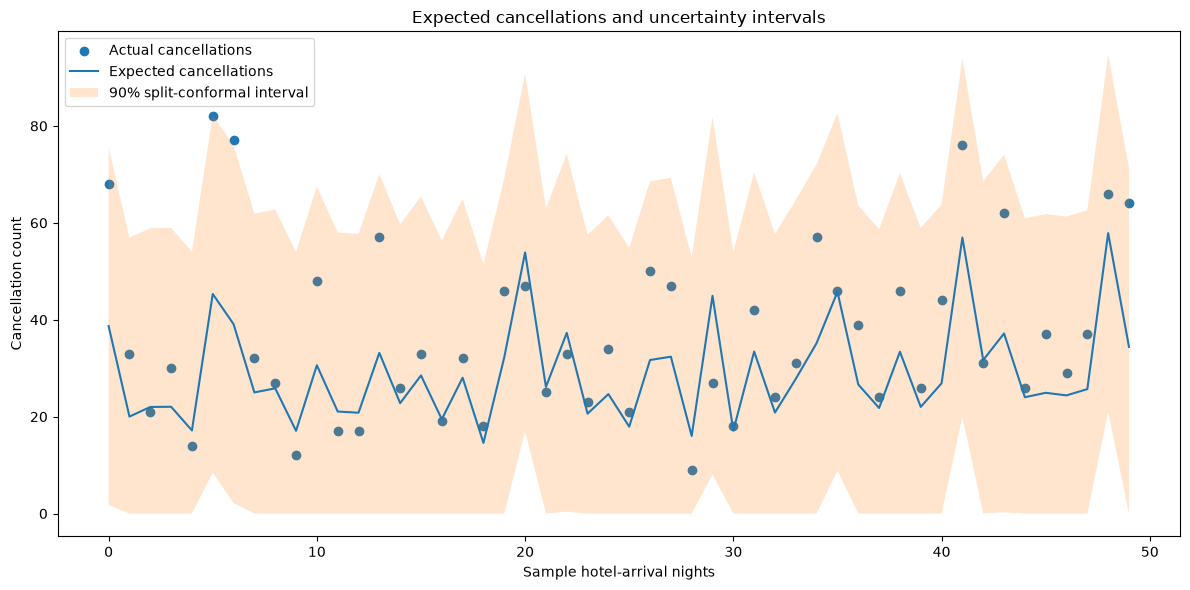

In [14]:
plot_data = choose_nights.reset_index().sort_values(
    ["hotel", "arrival_date"]
).head(50)

plt.figure(figsize=(12, 6))
x_positions = np.arange(len(plot_data))

plt.scatter(
    x_positions,
    plot_data["actual_cancellations"],
    label="Actual cancellations"
)

plt.plot(
    x_positions,
    plot_data["expected_cancellations"],
    label="Expected cancellations"
)

plt.fill_between(
    x_positions,
    plot_data["conformal_lower"],
    plot_data["conformal_upper"],
    alpha=0.2,
    label="90% split-conformal interval"
)

plt.xlabel("Sample hotel-arrival nights")
plt.ylabel("Cancellation count")
plt.title("Expected cancellations and uncertainty intervals")
plt.legend()
plt.tight_layout()
plt.show()

## 14. Save uncertainty evidence

We save the nightly tables and interval diagnostics. The Proof period remains unused.

In [15]:
evidence_folder = Path("evidence/uncertainty_conformal")
evidence_folder.mkdir(parents=True, exist_ok=True)

calibration_nights.to_csv(
    evidence_folder / "train_calibration_nightly_residuals.csv"
)

choose_nights.to_csv(
    evidence_folder / "choose_nightly_uncertainty_intervals.csv"
)

interval_results.to_csv(
    evidence_folder / "choose_interval_summary.csv",
    index=False
)

hotel_interval_results.to_csv(
    evidence_folder / "choose_hotel_interval_summary.csv",
    index=False
)

pd.DataFrame([{
    "nominal_coverage": 1 - ALPHA,
    "calibration_nights": number_calibration_nights,
    "conformal_rank": conformal_rank,
    "conformal_residual_quantile": conformal_quantile
}]).to_csv(
    evidence_folder / "conformal_settings.csv",
    index=False
)

print("Saved uncertainty evidence to:", evidence_folder)

Saved uncertainty evidence to: evidence\uncertainty_conformal


## 15. Interpretation, limitations and questions

### What this notebook establishes

- A probability model gives an expected nightly cancellation count.
- The Bernoulli variance sum gives a model-based spread under an independence assumption.
- A split-conformal residual quantile gives an empirical interval based on held-out Train hotel-nights.
- Coverage and width must be examined together, including separately by hotel.

### What it does not establish

- It does not estimate physical room capacity or occupancy.
- It does not establish the number of guests who would actually be walked.
- It does not guarantee 90% coverage under temporal dependence or distribution shift.
- It does not prove cancellation outcomes are independent.
- It does not choose an overbooking buffer or operating policy.

### Questions

1. Why is the sum of probabilities the expected number of cancellations?
2. Why do we add the Bernoulli variances when outcomes are assumed independent?
3. What does the conformal residual quantile represent?
4. Why might time dependence weaken conformal coverage?
5. Why should a hotel manager care about both interval coverage and interval width?

**Next notebook:** `11_choose_policy_selection.ipynb`, where expected cancellations and uncertainty are translated into candidate oversell policies and assessed against the client's walk guardrail.